# INTRODUCCIÓN: CONCEPTOS BÁSICOS SOBRE DIAGNÓSTICO DEL CÁNCER DE MAMA

El cáncer de mama es un tipo de cáncer que se origina en el tejido mamario debido al crecimiento anormal de células. El cáncer de mama puede darse tanto en hombres como en mujeres.

Clasificaciones para describir el estado de la enfermedad de cáncer de mama:

1) El TNM, que es el sistema estándar internacional para describir la exténsión anatómica del cáncer. En cáncer de mama, las letras significan:

- T (Tumor): tamaño y extensión del tumor primario --> Columna: 'T Stage' y 'Tumor Size'
- N (Nodes): afectación de ganglios linfáticos regionales --> Columna: 'N Stage'
- M (Metastasis): presencia o ausencia de metástasis a distancia. 

2) 6th Stage, que es el estadio clínico del cáncer de mama según la clasificación AJCC (6.ª edición), que refleja el grado de extensión de la enfermedad.

3) Grado de diferenciación tumoral, que explica cuanto se parecen las células cancerígenas a las células mamarias normales --> Columnas: 'Grade' y 'differentiate'.

4) A Stage, que en este dataset define la localización del tumor, es decir, cuánto se ha extendido el tumor. 

5) Estrogen Status y Progesterone Status, indican si el cácer de mama está relacionado hormonalmente o no. Se utiliza para poner el tratamiento al paciente.

6) Regional Node Examined and Regional Node Positive, indican cuántos gánglios linfáticos regionales fueron examinados y cuántos de ellos dieron positivo.


Relaciones entre variables:

Relación TNM y Tumor Size:

| T Stage   | Tumor Size    | N Stage   | M | 
| ---   | ---   | ---   | ---   | 
| T1    | <= 2 cm   | N0    | M0    | 
| T1    | <= 2 cm   | N1    | M0    |
| T2    | > 2 <= 5 cm   | N0    | M0    | 
| T2    | > 2 <= 5 cm   | N1    | M0    | 
| T3    | > 5 cm    | N0 - N1   | M0    |
| T1 - T3   | Cualquier | N2 - N3   | M0    |
| T4    | Invasión de piel o pared torácica | Cualquier | M0    | 
| Cualquiera    | Cualquier | Cualquier | M1    | 

El mejor pronóstico de la enfermedad es cuanto menor sean todos los parámetros anteriores y M = 0 (ausencia de metástasis).

Relación Grade y Differenciate:

| Grade | Differenciate |
| ---   | --- |
| 1 | Well differentiated   |
| 2 | Moderately differentiated |
| 3 | Poorly differentiated |
| 4 | Undifferentiated  |

El mejor pronóstico de la enfermedad es cuanto más diferenciado (grado menor) esté el tumor.

Relación entre A Stage, N Stage y M:

| A Stage   | N Stage   | M |
| ---   | ---   | ---   |
| Localized | N0    | M0    |
| Regional  | N1 - N3   | M0    |
| Distant   | Cualquier | M1    |

El mejor pronóstico es cuanto más localizado esté el tumor.

In [ ]:
%pip install phik

In [2]:
import sys

!{sys.executable} -m pip install phik

   ---------------------------------------- 0.0/677.5 kB ? eta -:--:--
   ---------------------------------------- 677.5/677.5 kB 3.1 MB/s  0:00:00


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import os
import phik

from collections import Counter
from scipy.stats import mannwhitneyu, stats
from scipy import stats
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, SelectFromModel, RFE, SequentialFeatureSelector
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

## 1) CARGAR LOS DATOS

In [2]:
archivo = '../01 data/01 raw/Breast_Cancer.csv'
df = pd.read_csv(archivo)
df.columns = df.columns.str.strip() # por si alguna columna trae espacios
df.head()

,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive


In [3]:
df.info()
nulos = int(df.isna().sum().sum())
duplicadas = int(df.duplicated().sum())
print("Valores vacíos:", nulos)
print("Filas duplicadas:", duplicadas)

<class 'pandas.DataFrame'>
RangeIndex: 4024 entries, 0 to 4023
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Age                     4024 non-null   int64
 1   Race                    4024 non-null   str  
 2   Marital Status          4024 non-null   str  
 3   T Stage                 4024 non-null   str  
 4   N Stage                 4024 non-null   str  
 5   6th Stage               4024 non-null   str  
 6   differentiate           4024 non-null   str  
 7   Grade                   4024 non-null   str  
 8   A Stage                 4024 non-null   str  
 9   Tumor Size              4024 non-null   int64
 10  Estrogen Status         4024 non-null   str  
 11  Progesterone Status     4024 non-null   str  
 12  Regional Node Examined  4024 non-null   int64
 13  Reginol Node Positive   4024 non-null   int64
 14  Survival Months         4024 non-null   int64
 15  Status                  4024 non

El dataset tiene 4024 filas y 16 columnas. No tiene valores nulos y solo una fila repetida.

Al ser pacientes anonimizados, dos pacientes distintos pueden tener las mismas características para el cáncer y parecer que hay una duplicidad en sus datos. Por consiguiente, no se puede eliminar ninguna fila.

## 2) EL PROBLEMA

Queremos predecir la supervivencia en meses de pacientes de cáncer de mama con carcinoma ductal infiltrante y lobulillar infiltrante, para lo cual tenemos un dataset de 4024 pacientes femeninas diagnósticadas entre 2006 y 2010. Por lo que tenemos un proyecto de Machine Learning de Regresión.

## 3) EL TARGET

Nuestro target es la columna de 'Survival Months'. Por consiguiente, para que no haya una fuga de información procederé a eliminar la columna 'Status', que nos indica si la paciente esta viva o no, **antes de dividir en train y test.**

Se elimina la variable 'Status' porque no se conoce en el momento de predecir y va ligada al resultado. La columna 'Status' indica si es supervivencia real (la paciente ha fallecido) o solo es el tiempo que se la ha seguido (la paciente sigue viva).

La limitación de los datos es que no siguen hasta que todas las pacientes han fallecido, sino que se deja de recoger información en un determinado momento.

In [4]:
target = df['Survival Months']
df = df.drop(columns=['Status'])
print(df.columns.tolist())

['Age', 'Race', 'Marital Status', 'T Stage', 'N Stage', '6th Stage', 'differentiate', 'Grade', 'A Stage', 'Tumor Size', 'Estrogen Status', 'Progesterone Status', 'Regional Node Examined', 'Reginol Node Positive', 'Survival Months']


## 4) DIVIDIR EN TRAIN Y TEST

In [5]:
X_train, X_test, y_train, y_test = train_test_split(df.drop('Survival Months', axis=1),
                                                    df['Survival Months'],
                                                    test_size=0.2,
                                                    random_state=42)

In [6]:
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (3219, 14) | Test: (805, 14)


Después de dividir en train y test, nos quedan 3219 pacientes para entrenar el modelo y 805 para testearlo

In [37]:
# Guardar datos de entrenamiento
X_train.to_csv("../01 data/03 train/X_train.csv", index=False)
y_train.to_frame().to_csv("../01 data/03 train/y_train.csv", index=False)

# Guardar datos de test
X_test.to_csv("../01 data/04 test/X_test.csv", index=False)
y_test.to_frame().to_csv("../01 data/04 test/y_test.csv", index=False)

In [38]:
# Comprobación del directorio dónde se han guardado

print(os.listdir("../01 data/03 train"))
print(os.listdir("../01 data/04 test"))

['X_train.csv', 'y_train.csv']
['X_test.csv', 'y_test.csv']


## 5) EDA

5.1) EDA VARIABLE OBJETIVO

- Estadística descriptiva

In [7]:
y_train.describe()

count    3219.000000
mean       71.162162
std        22.869855
min         1.000000
25%        56.000000
50%        73.000000
75%        89.000000
max       107.000000
Name: Survival Months, dtype: float64

In [8]:
print("Media:", y_train.mean())
print("Mediana:", y_train.median())
print("Moda:", y_train.mode())
print("Varianza:", y_train.var())
print("Desviación típica:", y_train.std())
print("Coeficiente de variación:", y_train.std() / y_train.mean())
print("Asimetría:", y_train.skew())
print("Curtosis:", y_train.kurtosis())

Media: 71.16216216216216
Mediana: 73.0
Moda: 0    69
Name: Survival Months, dtype: int64
Varianza: 523.0302521290713
Desviación típica: 22.869854659115596
Coeficiente de variación: 0.3213766131360718
Asimetría: -0.5800899664045127
Curtosis: -0.0028909026993471088


In [9]:
percentiles = y_train.quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print(percentiles)

0.01      9.0
0.05     27.0
0.10     43.0
0.25     56.0
0.50     73.0
0.75     89.0
0.90    100.0
0.95    103.0
0.99    107.0
Name: Survival Months, dtype: float64


La mitad de las pacientes presenta una supervivencia comprendida entre 56 y 89 meses, con una mediana de 73 meses. La media (71,16 meses) es ligeramente inferior a la mediana, mientras que la moda es de 69 meses, lo que sugiere una distribución relativamente centrada en valores elevados de supervivencia.

La distribución presenta una asimetría negativa moderada (asimetría = -0,58), indicando una cola algo más larga hacia los valores bajos de supervivencia. Esto significa que la mayoría de las pacientes se concentra en supervivencias medias y altas, mientras que un número menor de pacientes presenta supervivencias notablemente inferiores. Esta interpretación también es coherente con los percentiles observados, donde el 90 % de las pacientes supera los 43 meses de supervivencia y solo el 1 % presenta valores inferiores a 9 meses.

La desviación típica de 22,87 meses indica una dispersión moderada alrededor de la media. Aplicando la regla de una desviación típica, aproximadamente dos tercios de las observaciones se situarían entre 48,29 y 94,03 meses (media ± desviación típica), aunque esta interpretación es únicamente orientativa al no asumir estrictamente normalidad.

El coeficiente de variación (0,32) indica una variabilidad moderada, ya que la desviación típica representa alrededor del 32 % de la media. Por tanto, la supervivencia muestra una dispersión apreciable, pero no excesivamente elevada en relación con su valor medio.

Por último, la curtosis es prácticamente nula (-0,003), lo que indica que la distribución es muy similar a una distribución normal en cuanto a concentración y peso de las colas. Aunque el valor es ligeramente negativo, la diferencia es tan pequeña que no puede afirmarse que la distribución sea significativamente más plana que una normal.

- Análisis visual: distribución y outliers

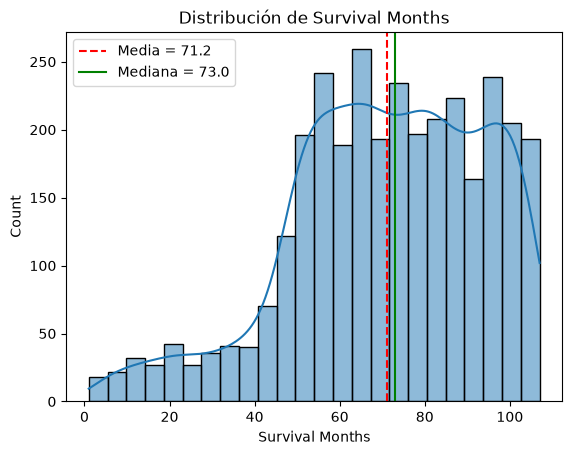

In [10]:
sns.histplot(y_train, kde=True)
plt.axvline(y_train.mean(), color="red", ls="--", label=f"Media = {y_train.mean():.1f}")
plt.axvline(y_train.median(), color="green", ls="-", label=f"Mediana = {y_train.median():.1f}")
plt.title("Distribución de Survival Months")
plt.legend()
plt.show()

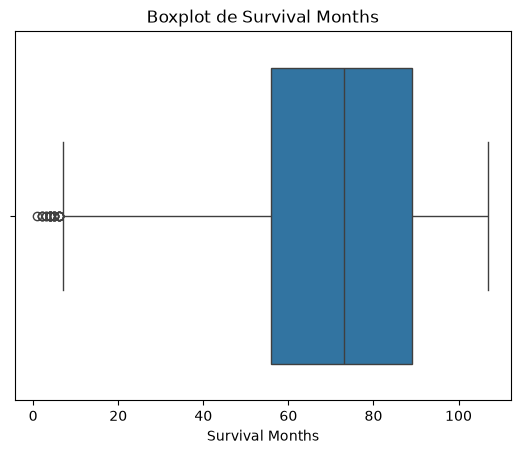

In [11]:
sns.boxplot(x=y_train)
plt.title('Boxplot de Survival Months')
plt.show()

El histograma muestra una distribución no normal, con una mayor concentración de pacientes entre aproximadamente 50 y 107 meses de supervivencia y una menor frecuencia de valores bajos. Esto es consistente con la asimetría negativa moderada observada (−0,58), que indica una cola más larga hacia las supervivencias reducidas. El boxplot confirma que el 50 % central de las observaciones se concentra entre 56 y 89 meses, identificándose únicamente algunos valores atípicos bajos. En conjunto, los resultados reflejan una población con predominio de supervivencias medias y altas, aunque con una dispersión moderada y la presencia de un pequeño grupo de pacientes con supervivencias notablemente inferiores.

- Detección de outliers

In [12]:
# Detección de outliers en la variable objetivo usando solo y_train

Q1 = y_train.quantile(0.25)
Q3 = y_train.quantile(0.75)

IQR = Q3 - Q1

lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

outliers = y_train[
    (y_train < lim_inf) |
    (y_train > lim_sup)
]

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Límite inferior: {lim_inf:.2f}")
print(f"Límite superior: {lim_sup:.2f}")

print(f"\nNúmero de outliers: {len(outliers)}")
print(f"Porcentaje de outliers: {100 * len(outliers) / len(y_train):.2f}%")

Q1: 56.00
Q3: 89.00
IQR: 33.00
Límite inferior: 6.50
Límite superior: 138.50

Número de outliers: 24
Porcentaje de outliers: 0.75%


Hay 24 pacientes (0.7 %) con valores raros: 24 por debajo de 6.5 meses y 0 por encima de 138.5. Son supervivencias muy cortas, algo que ocurre en la realidad y no parece un error de registro. Por consiguiente, mantendremos los outliers.

- Evaluación de la normalidad

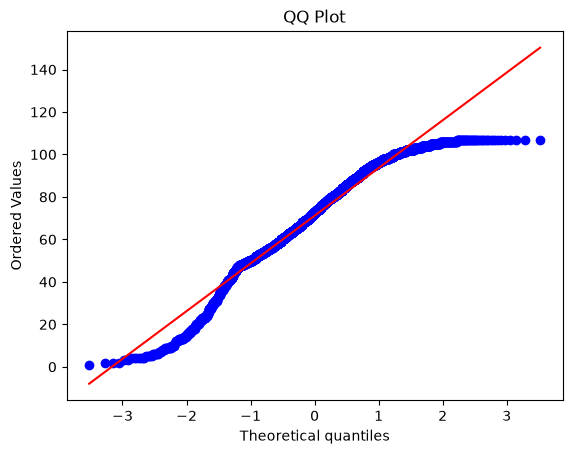

In [13]:
stats.probplot(
    y_train,
    dist="norm",
    plot=plt
)

plt.title("QQ Plot")
plt.show()

In [14]:
# Evaluación de normalidad: Test Shapiro-Wilk

from scipy.stats import shapiro

sample = y_train.sample(
    min(5000, len(y_train)),
    random_state=42
)

stat, p = shapiro(sample)

print("Estadístico:", stat)
print("p-value:", p)

if p > 0.05:
    print("No se rechaza la hipótesis de normalidad")
else:
    print("Se rechaza la hipótesis de normalidad")

Estadístico: 0.9632651711820087
p-value: 7.283486018408745e-28
Se rechaza la hipótesis de normalidad


No sigue una distribución normal (Shapiro p = 7.3e-28); en el QQ plot los puntos se separan de la recta, sobre todo en los extremos. Con tantas pacientes el test es muy exigente, así que lo que realmente importará es revisar los errores del modelo más adelante

- Transformaciones para conseguir una distribución normal en la variable objetivo

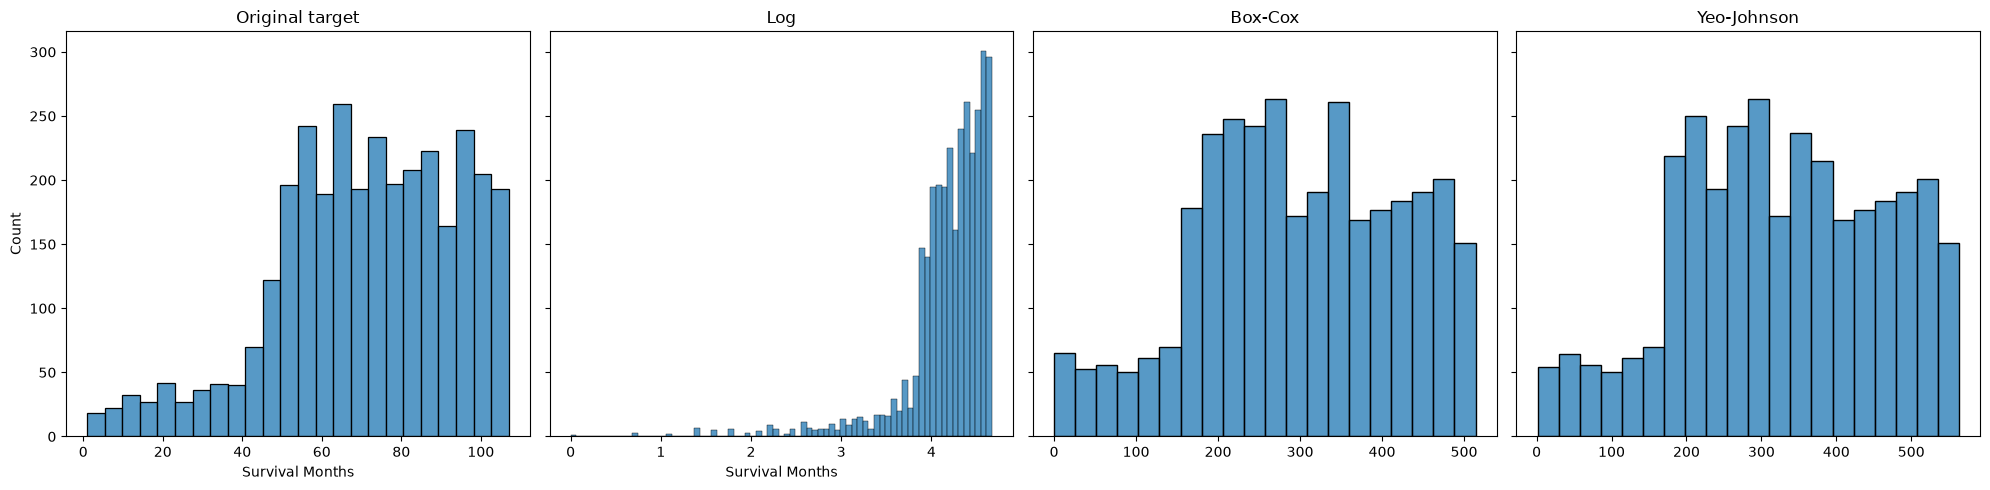

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

# Original target
sns.histplot(y_train, kde=False, ax=axes[0])
axes[0].set_title("Original target")

# Logaritmic
sns.histplot(np.log(y_train),kde=False, ax=axes[1])
axes[1].set_title("Log")

# Box-cox
sns.histplot(stats.boxcox(y_train)[0],kde=False, ax=axes[2])
axes[2].set_title("Box-Cox");

# Yeo-Johnson
pt = PowerTransformer(method='yeo-johnson', standardize=False)
y_yj = pt.fit_transform(y_train.to_numpy().reshape(-1, 1)).flatten()

sns.histplot(y_yj, kde=False, ax=axes[3])
axes[3].set_title("Yeo-Johnson")

plt.tight_layout()
plt.show()

In [16]:
y_train_log = np.log1p(y_train)

In [17]:
print("Variable original")
print("Asimetría:", y_train.skew())
print("Curtosis:", y_train.kurtosis())

print("\nTransformación log1p")
print("Asimetría:", y_train_log.skew())
print("Curtosis:", y_train_log.kurtosis())

Variable original
Asimetría: -0.5800899664045127
Curtosis: -0.0028909026993471088

Transformación log1p
Asimetría: -2.5792797437729593
Curtosis: 9.743237550556735


In [18]:
from scipy.stats import boxcox

y_train_boxcox, lambda_bc = boxcox(y_train)

print("Lambda:", lambda_bc)
print("Asimetría:", pd.Series(y_train_boxcox).skew())
print("Curtosis:", pd.Series(y_train_boxcox).kurtosis())

print("Lambda Yeo-Johnson:", pt.lambdas_[0])
print("Asimetría:", stats.skew(y_yj))
print("Curtosis:", stats.kurtosis(y_yj))

Lambda: 1.4096015934258255
Asimetría: -0.20259781047886874
Curtosis: -0.6806283998857561
Lambda Yeo-Johnson: 1.4294634568638376
Asimetría: -0.1940894449548102
Curtosis: -0.6902139207850482


Evaluamos la transformación logarítmica sobre la variable objetivo, Survival Months, con el fin de mejorar su aproximación a una distribución normal. Sin embargo, los resultados mostraron un emperoramiento significativo en la distribución por las siguientes razones: la asimetría pasa de -0.58 a -2.58, pasando a tener una fuerte asimetría negativa y Curtosis pasó de tener un valor prácticamente de 0 a 9.74, pasando a tener una distribución muy alejada de la normalidad. Por tanto, lo mejor es no transformar Survival Months mediante logaritmos, y continuar trabajando con la variable original.

Evaluamos las transformaciones de Box-Cox y Yeo-Johnson sobre la variable objetivo Survival Months. Ambas redujeron significativamente la asimetría respecto a la distribución original, pasando de -0.58 a valores próximos a -0.20. Los parámetros λ obtenidos fueron muy similares (1.41 para Box-Cox y 1.43 para Yeo-Johnson), lo que indica que ambas transformaciones producen efectos prácticamente equivalentes sobre los datos. Aunque dichas transformaciones mejoran ligeramente las propiedades estadísticas de la variable objetivo, la distribución original ya presentaba una asimetría moderada y una curtosis prácticamente nula. Por lo que la ganancia es limitada y no justifica la pérdida de lectura en meses. Por lo tanto, decidimos no transformar la variable original.

- Punto de Referencia: Baseline

¿Qué error se comete si se responde siempre lo mismo (la media o la mediana de train), calculado con validación cruzada dentro de train?

In [19]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.dummy import DummyRegressor

X_dummy = np.zeros((len(y_train), 1))
cv = KFold(n_splits=5, shuffle=True, random_state=42)

filas = {}
for estrategia in ["mean", "median"]:
    res = cross_validate(
        DummyRegressor(strategy=estrategia), X_dummy, y_train, cv=cv,
        scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"},
    )
    filas[estrategia] = {"MAE": -res["test_MAE"].mean(), "RMSE": -res["test_RMSE"].mean()}

baseline = pd.DataFrame(filas).T.round(2)
mae_dummy = baseline.loc["mean", "MAE"]
baseline

,MAE,RMSE
mean,18.59,22.87
median,18.56,22.93


Si el modelo respondiera siempre la media, se equivocaría de media en unos 18.6 meses. Ese es el listón que tiene que superar cualquier modelo.

5.2) EDA VARIABLES CON VARIABLE OBJETIVO

In [20]:
# Reporte de variables:

def data_report(df):
    # Sacamos los NOMBRES
    cols = pd.DataFrame(df.columns.values, columns=["COL_N"])

    # Sacamos los TIPOS
    types = pd.DataFrame(df.dtypes.values, columns=["DATA_TYPE"])

    # Sacamos los MISSINGS
    percent_missing = round(df.isnull().sum() * 100 / len(df), 2)
    percent_missing_df = pd.DataFrame(percent_missing.values, columns=["MISSINGS (%)"])

    # Sacamos los VALORES UNICOS
    unicos = pd.DataFrame(df.nunique().values, columns=["UNIQUE_VALUES"])
    
    percent_cardin = round(unicos['UNIQUE_VALUES']*100/len(df), 2)
    percent_cardin_df = pd.DataFrame(percent_cardin.values, columns=["CARDIN (%)"])

    concatenado = pd.concat([cols, types, percent_missing_df, unicos, percent_cardin_df], axis=1, sort=False)
    concatenado.set_index('COL_N', drop=True, inplace=True)


    return concatenado.T
        
data_report(X_train)

COL_N,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive
DATA_TYPE,int64,str,str,str,str,str,str,str,str,int64,str,str,int64,int64
MISSINGS (%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
UNIQUE_VALUES,40,3,5,4,3,5,4,4,2,104,2,2,53,37
CARDIN (%),1.24,0.09,0.16,0.12,0.09,0.16,0.12,0.12,0.06,3.23,0.06,0.06,1.65,1.15


In [21]:
# Listas de variables numéricas y categóricas (se sacan de los datos, no a mano)
features_num = X_train.select_dtypes(include='number').columns.to_list()
features_cat = X_train.select_dtypes(exclude='number').columns.to_list()

print("Numéricas:", features_num)
print("Categóricas:", features_cat)

Numéricas: ['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive']
Categóricas: ['Race', 'Marital Status', 'T Stage', 'N Stage', '6th Stage', 'differentiate', 'Grade', 'A Stage', 'Estrogen Status', 'Progesterone Status']


Tenemos tanto variables categóricas como numéricas. No tenemos missing values en ninguna de nuestras variables, como ya se vió en el apartado de limpieza de datos, por lo que no tenemos que hacer ninguna transformación en ellas.

- Análisis de cada variable por separado (análisis univariante)

Variables numéricas: forma, valores raros y asimetría

In [22]:
X_train[features_num].describe().round(2)

,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
count,3219.00,3219.00,3219.00,3219.00
mean,53.83,30.33,14.27,4.22
std,9.00,20.75,8.11,5.19
min,30.00,1.00,1.00,1.00
25%,47.00,16.00,9.00,1.00
50%,54.00,25.00,14.00,2.00
75%,61.00,38.00,19.00,5.00
max,69.00,140.00,61.00,46.00


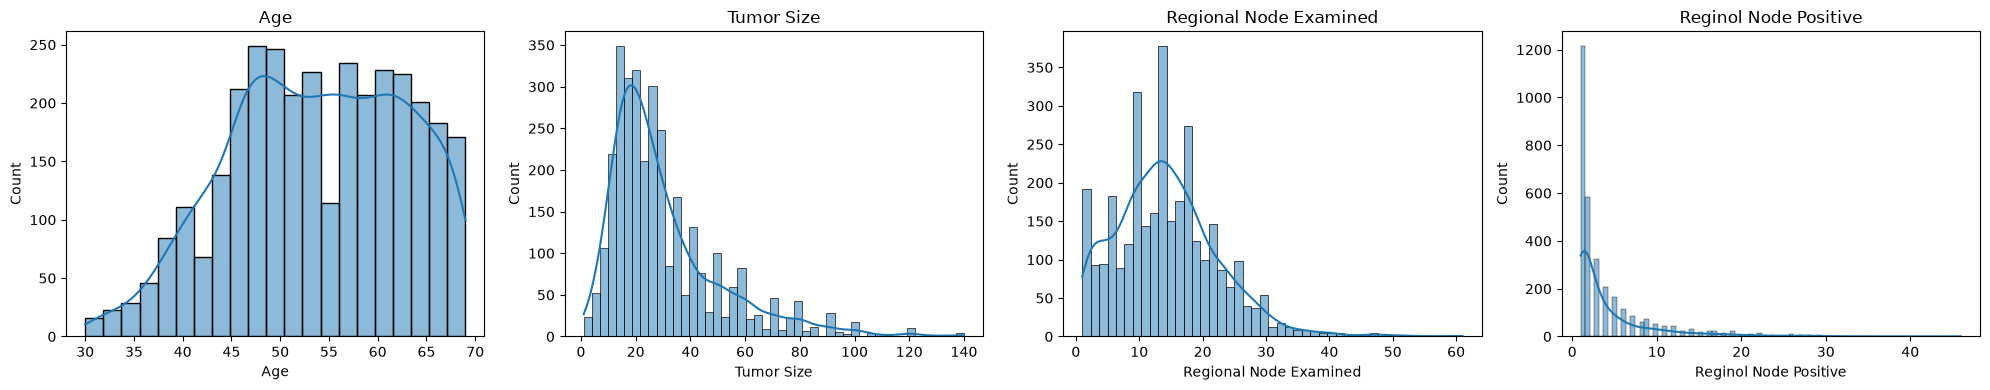

In [23]:
fig, axes = plt.subplots(1, len(features_num), figsize=(5 * len(features_num), 4))

for ax, col in zip(axes, features_num):
    sns.histplot(X_train[col], kde=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

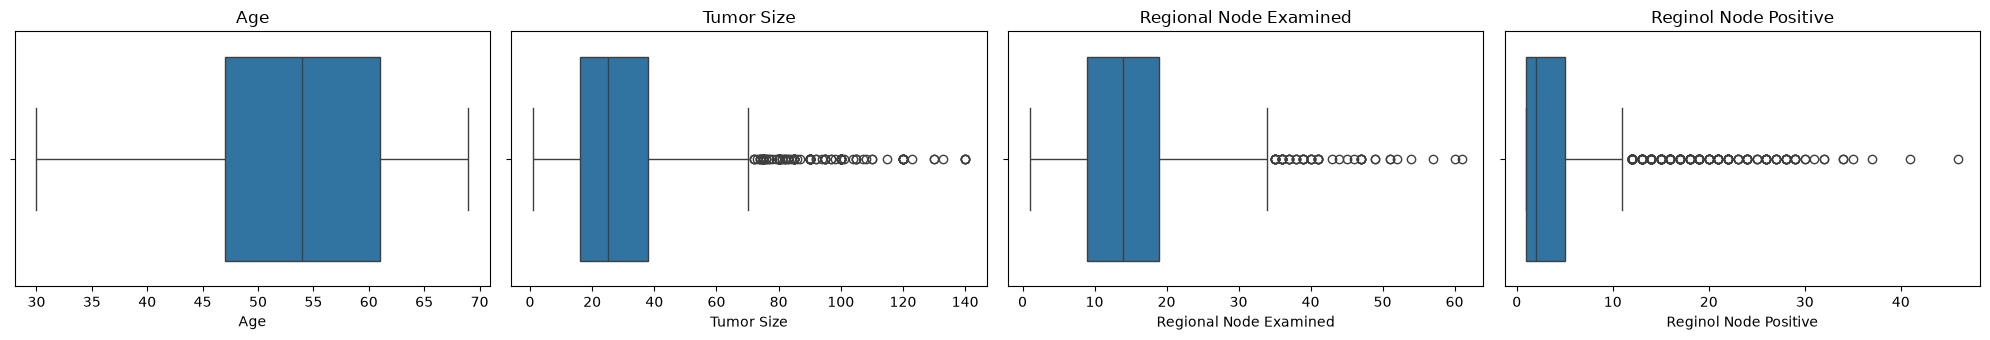

In [24]:
fig, axes = plt.subplots(1, len(features_num), figsize=(5 * len(features_num), 3.5))

for ax, col in zip(axes, features_num):
    sns.boxplot(x=X_train[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [25]:
# Outliers por variable (criterio del rango intercuartílico) y asimetría
filas = []
for col in features_num:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((X_train[col] < lim_inf) | (X_train[col] > lim_sup)).sum())
    filas.append({
        'Variable': col,
        'Mínimo': X_train[col].min(),
        'Máximo': X_train[col].max(),
        'Asimetría': X_train[col].skew(),
        'Nº outliers': n_out,
        '% outliers': 100 * n_out / len(X_train),
    })

tabla_num = pd.DataFrame(filas).set_index('Variable').round(2)
tabla_num

,Mínimo,Máximo,Asimetría,Nº outliers,% outliers
Variable,,,,,
Age,30,69,-0.21,0,0.00
Tumor Size,1,140,1.69,173,5.37
Regional Node Examined,1,61,0.85,55,1.71
Reginol Node Positive,1,46,2.66,284,8.82


Las variables con cola larga hacia valores altos (asimetría mayor que 1) son: Tumor Size, Reginol Node Positive. Valores raros por variable: Age (0), Tumor Size (173), Regional Node Examined (55), Reginol Node Positive (284). No se eliminan: tumores grandes o muchos ganglios afectados son casos reales y justo los más graves. Para modelos lineales se puede probar el logaritmo en las de cola larga; los modelos de árboles no lo necesitan.

Variables categóricas: cuántas pacientes hay en cada categoría.

In [26]:
for col in features_cat:
    print(f"\n{col}")
    print(X_train[col].value_counts().to_frame("n").join(X_train[col].value_counts(normalize=True).round(3).rename("proporción")))


Race
          n  proporción
Race                   
White  2709       0.842
Other   271       0.084
Black   239       0.074

Marital Status
                   n  proporción
Marital Status                  
Married         2103       0.653
Single           519       0.161
Divorced         376       0.117
Widowed          188       0.058
Separated         33       0.010

T Stage
            n  proporción
T Stage                  
T2       1430       0.444
T1       1281       0.398
T3        418       0.130
T4         90       0.028

N Stage
            n  proporción
N Stage                  
N1       2176       0.676
N2        654       0.203
N3        389       0.121

6th Stage
              n  proporción
6th Stage                  
IIA        1030       0.320
IIB         908       0.282
IIIA        830       0.258
IIIC        389       0.121
IIIB         62       0.019

differentiate
                              n  proporción
differentiate                              
Moderately di

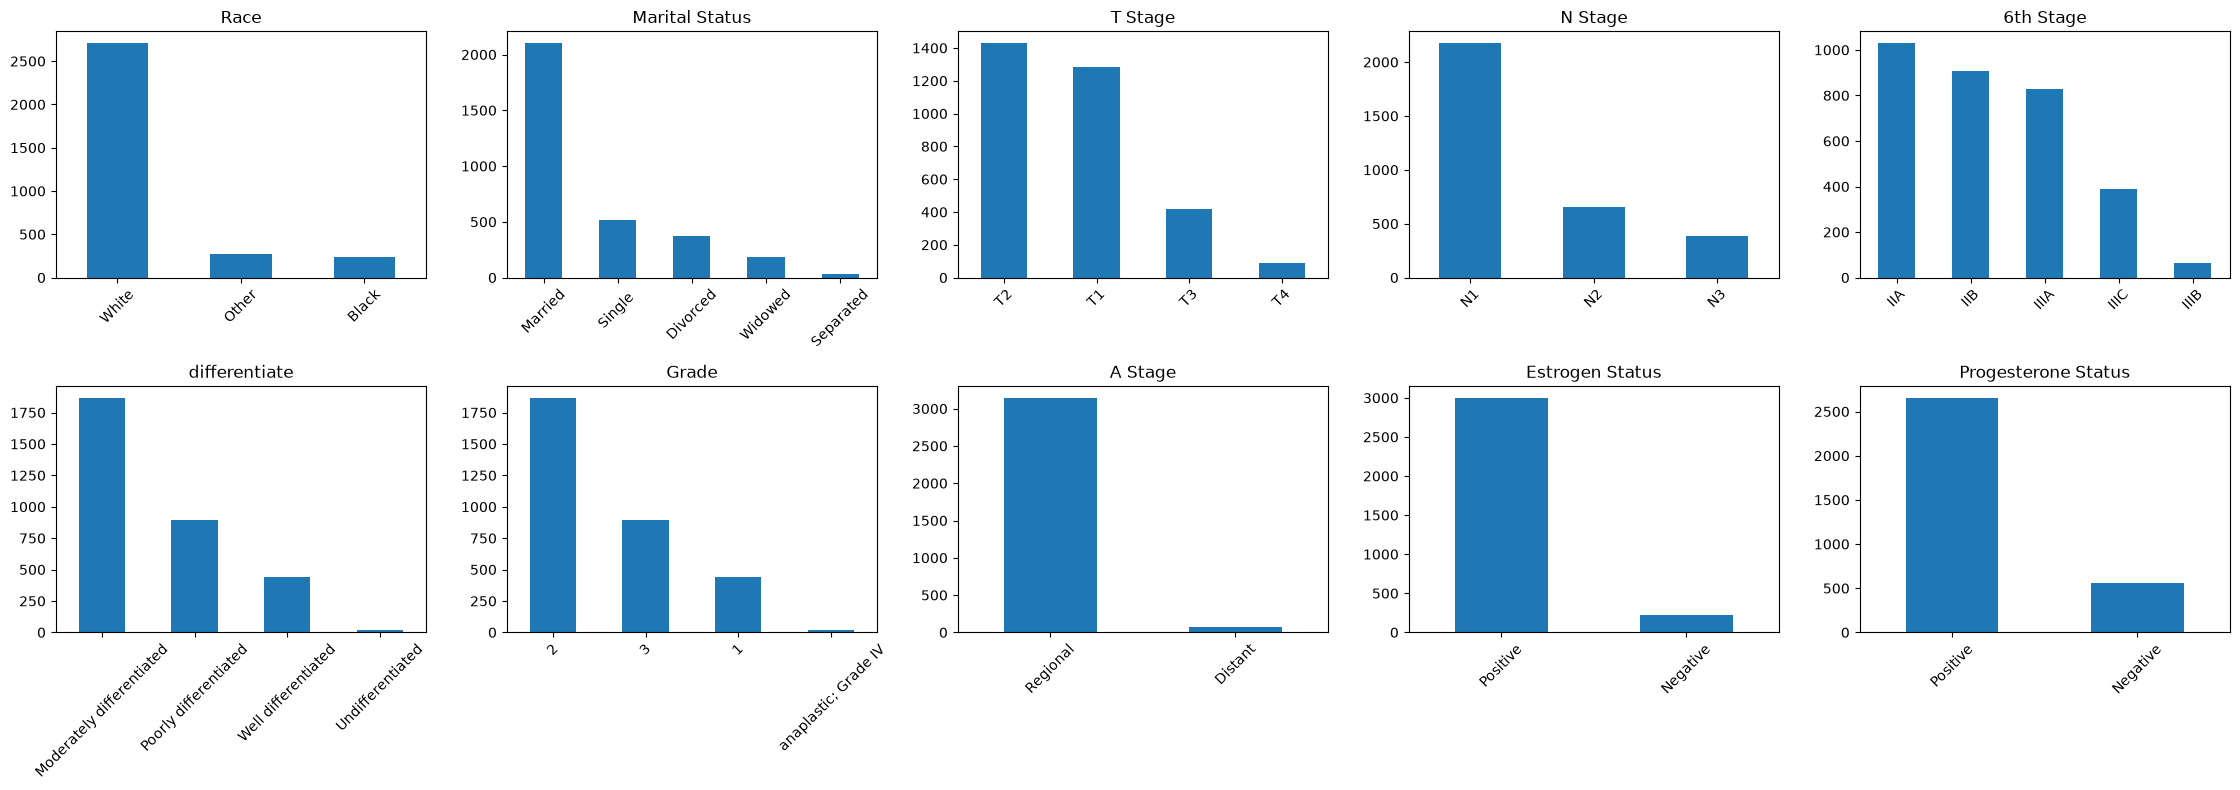

In [27]:
n_cols = 5
n_filas = int(np.ceil(len(features_cat) / n_cols))
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4.5 * n_cols, 4 * n_filas))
axes = np.array(axes).ravel()

for ax, col in zip(axes, features_cat):
    X_train[col].value_counts().plot(kind='bar', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)

for ax in axes[len(features_cat):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

Categorías con menos del 1 % de las pacientes: differentiate = Undifferentiated (0.5%); Grade = anaplastic; Grade IV (0.5%). Con tan pocos casos no se puede aprender nada fiable de ellas, así que habrá que agruparlas con otra categoría o tratarlas con cuidado. Los receptores hormonales están muy desbalanceados: 93% de las pacientes es «Positive» en Estrogen Status y 82% es «Positive» en Progesterone Status.

- Correlación lineal variables numéricas

In [28]:
# Correlación de Pearson

train_df = X_train.copy()
train_df['Survival Months'] = y_train

corr_target = (
    train_df
    .corr(numeric_only=True)['Survival Months']
    .sort_values(ascending=False)
)

print(corr_target)

Survival Months           1.000000
Age                      -0.015292
Regional Node Examined   -0.019663
Tumor Size               -0.083942
Reginol Node Positive    -0.122360
Name: Survival Months, dtype: float64


In [29]:
# Variables más correlacionadas

corr_target.drop('Survival Months').sort_values(key=abs, ascending=False)

Reginol Node Positive    -0.122360
Tumor Size               -0.083942
Regional Node Examined   -0.019663
Age                      -0.015292
Name: Survival Months, dtype: float64

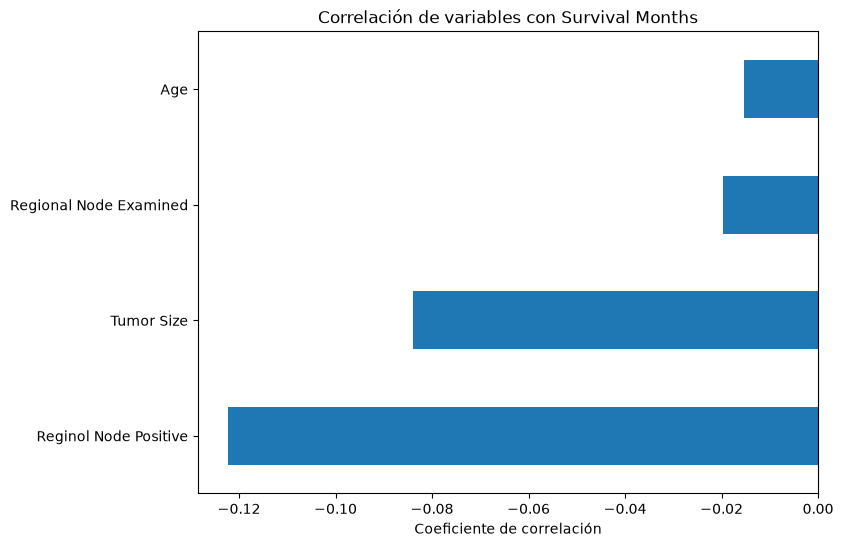

In [30]:
# Gráfico de correlaciones

plt.figure(figsize=(8,6))

corr_target.drop('Survival Months').sort_values().plot(kind='barh')

plt.title('Correlación de variables con Survival Months')
plt.xlabel('Coeficiente de correlación')
plt.show()

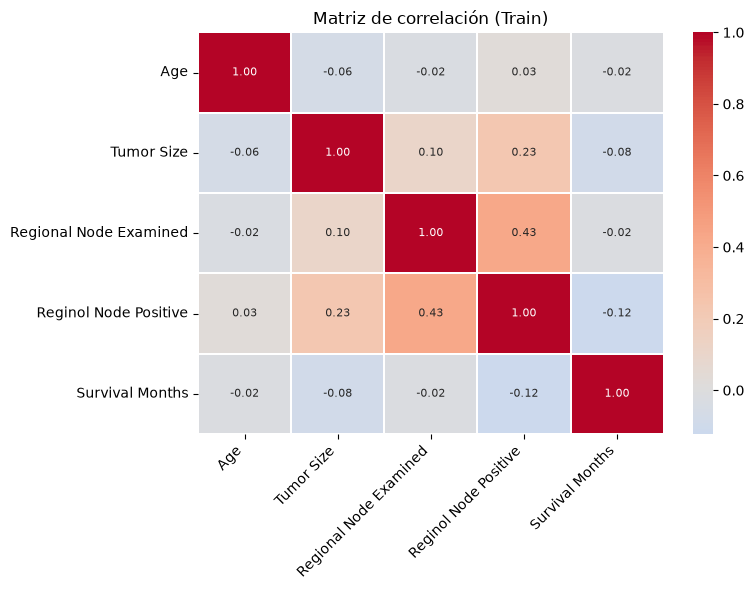

In [31]:
# Heatmap de correlaciones

plt.figure(figsize=(8, 6))

sns.heatmap(
    train_df.corr(numeric_only=True),
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 8},
    linewidths=0.3
)

plt.title('Matriz de correlación (Train)')

# Rotar etiquetas del eje X
plt.xticks(rotation=45, ha='right')

# Mantener horizontales las del eje Y
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [32]:
# Pearson solo mide relaciones en línea recta. Spearman (por orden) y el gráfico por tramos detectan otras formas.
corr_spearman = (
    train_df.corr(method='spearman', numeric_only=True)['Survival Months']
    .drop('Survival Months')
)
print("Correlación de Spearman con Survival Months:")
print(corr_spearman.sort_values(key=abs, ascending=False).round(3))

Correlación de Spearman con Survival Months:
Reginol Node Positive    -0.102
Tumor Size               -0.079
Age                      -0.021
Regional Node Examined   -0.004
Name: Survival Months, dtype: float64


Al ordenar las pacientes según sus meses de supervivencia, apenas se observan patrones claros asociados a las variables numéricas estudiadas. La variable que más relación muestra es el número de ganglios positivos, seguida del tamaño tumoral, pero ambas relaciones son muy débiles.

Lo que quiere decir que, conocer únicamente la edad, el tamaño del tumor, el número de ganglios examinados o el número de ganglios positivos permite explicar muy poco sobre cuánto tiempo sobrevivirá una paciente. Aunque existe una ligera tendencia a que las pacientes con más ganglios afectados o tumores más grandes presenten una menor supervivencia, esa tendencia es demasiado débil para realizar predicciones precisas. Estos resultados coinciden con el resto de los análisis realizados, donde ninguna variable individual ha mostrado una capacidad predictiva significativa sobre la variable objetivo Survival Months.

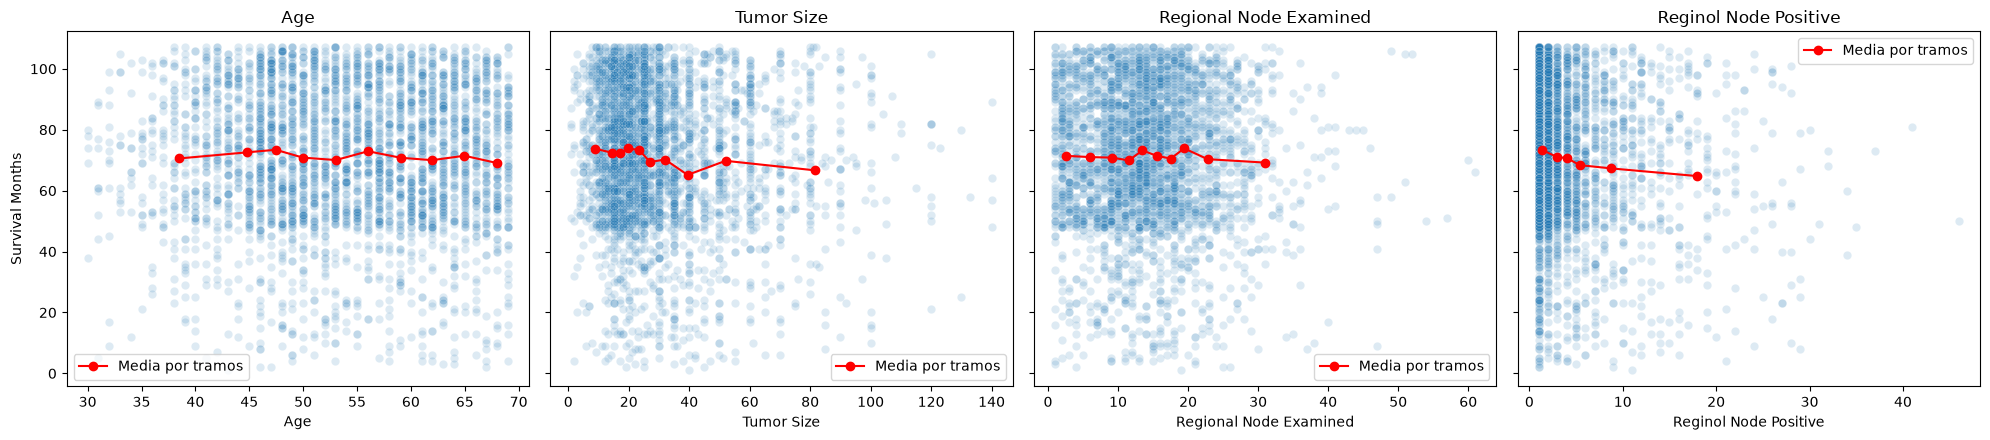

In [33]:
# Cada punto es una paciente; la línea roja es la media de meses por tramos de la variable
fig, axes = plt.subplots(1, len(features_num), figsize=(5 * len(features_num), 4.5), sharey=True)

for ax, col in zip(axes, features_num):
    sns.scatterplot(x=X_train[col], y=y_train, alpha=0.15, ax=ax)
    tramos = pd.qcut(X_train[col], q=10, duplicates='drop')
    media_meses = y_train.groupby(tramos, observed=True).mean()
    centro_tramo = X_train[col].groupby(tramos, observed=True).mean()
    ax.plot(centro_tramo.values, media_meses.values, color='red', marker='o', label='Media por tramos')
    ax.set_title(col)
    ax.set_ylabel('Survival Months')
    ax.legend()

plt.tight_layout()
plt.show()

Ninguna variable numérica se relaciona de forma clara con los meses de supervivencia. La más fuerte es Reginol Node Positive (-0.12), seguida de Tumor Size (-0.08); con Spearman el valor más alto es 0.10, así que no se esconde nada que Pearson no viera. En los gráficos por tramos la línea roja es casi plana o con poca pendiente. A más ganglios positivos y tumor más grande, algo menos de meses, pero con mucha diferencia entre pacientes.

- Colinealidad entre variables numéricas

In [34]:
# Matriz de correlación de las variables predictoras
corr = X_train.corr(numeric_only=True)

features_num = X_train.select_dtypes(include=['int64', 'float64']).columns.to_list()

criterio_col = 0.7

excluidas = []

for col in features_num:

    print(f"\nVoy a comprobar la colinealidad con {col}")

    if col not in excluidas:

        for col_2, valor_corr in corr[col].items():

            print(f"Comprobando con {col_2}")

            if col == col_2:

                print("Soy yo misma, no me excluyo")

            elif col_2 in features_num:

                if abs(valor_corr) >= criterio_col:

                    print(f"Correlación = {valor_corr:.3f}, ", f"por eso excluyo a {col_2}")
                        
                    excluidas.append(col_2)

                else:
                    print(f"Correlación = {valor_corr:.3f}. ",f"Sin problemas de colinealidad.")

            else:
                print("La variable no está en la lista de variables numéricas.")

# Eliminar duplicados
excluidas = list(set(excluidas))

print("\nVariables excluidas:")
print(excluidas)


Voy a comprobar la colinealidad con Age
Comprobando con Age
Soy yo misma, no me excluyo
Comprobando con Tumor Size
Correlación = -0.062.  Sin problemas de colinealidad.
Comprobando con Regional Node Examined
Correlación = -0.024.  Sin problemas de colinealidad.
Comprobando con Reginol Node Positive
Correlación = 0.030.  Sin problemas de colinealidad.

Voy a comprobar la colinealidad con Tumor Size
Comprobando con Age
Correlación = -0.062.  Sin problemas de colinealidad.
Comprobando con Tumor Size
Soy yo misma, no me excluyo
Comprobando con Regional Node Examined
Correlación = 0.103.  Sin problemas de colinealidad.
Comprobando con Reginol Node Positive
Correlación = 0.231.  Sin problemas de colinealidad.

Voy a comprobar la colinealidad con Regional Node Examined
Comprobando con Age
Correlación = -0.024.  Sin problemas de colinealidad.
Comprobando con Tumor Size
Correlación = 0.103.  Sin problemas de colinealidad.
Comprobando con Regional Node Examined
Soy yo misma, no me excluyo
Compr

In [35]:
# Análisis de multicolinealidad mediante VIF

from statsmodels.stats.outliers_influence import variance_inflation_factor

X_num = X_train.select_dtypes(include='number')

vif = pd.DataFrame({
    'Variable': X_num.columns,
    'VIF': [
        variance_inflation_factor(X_num.values, i)
        for i in range(X_num.shape[1])
    ]
})

vif.sort_values('VIF', ascending=False)

,Variable,VIF
3,Reginol Node Positive,1.280895
2,Regional Node Examined,1.223252
1,Tumor Size,1.061807
0,Age,1.007474


In [36]:
# Estudio de variables altamente correlacionadas

corr_matrix = X_train.corr(numeric_only=True)

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr = [
    col
    for col in upper.columns
    if any(abs(upper[col]) > 0.7)
]

print("Variables candidatas a excluir:")
print(high_corr)

Variables candidatas a excluir:
[]


Las variables numéricas no se repiten entre sí. La pareja más parecida es Regional Node Examined con Reginol Node Positive (correlación de 0.43, lejos del 0,7 que haría saltar la alarma), y el VIF más alto es 1.28 (Reginol Node Positive), muy por debajo de 5. No hay que quitar ninguna por este motivo. La repetición de información está en las categóricas, que se ve a continuación.

- Asociación de las variables categóricas con el target

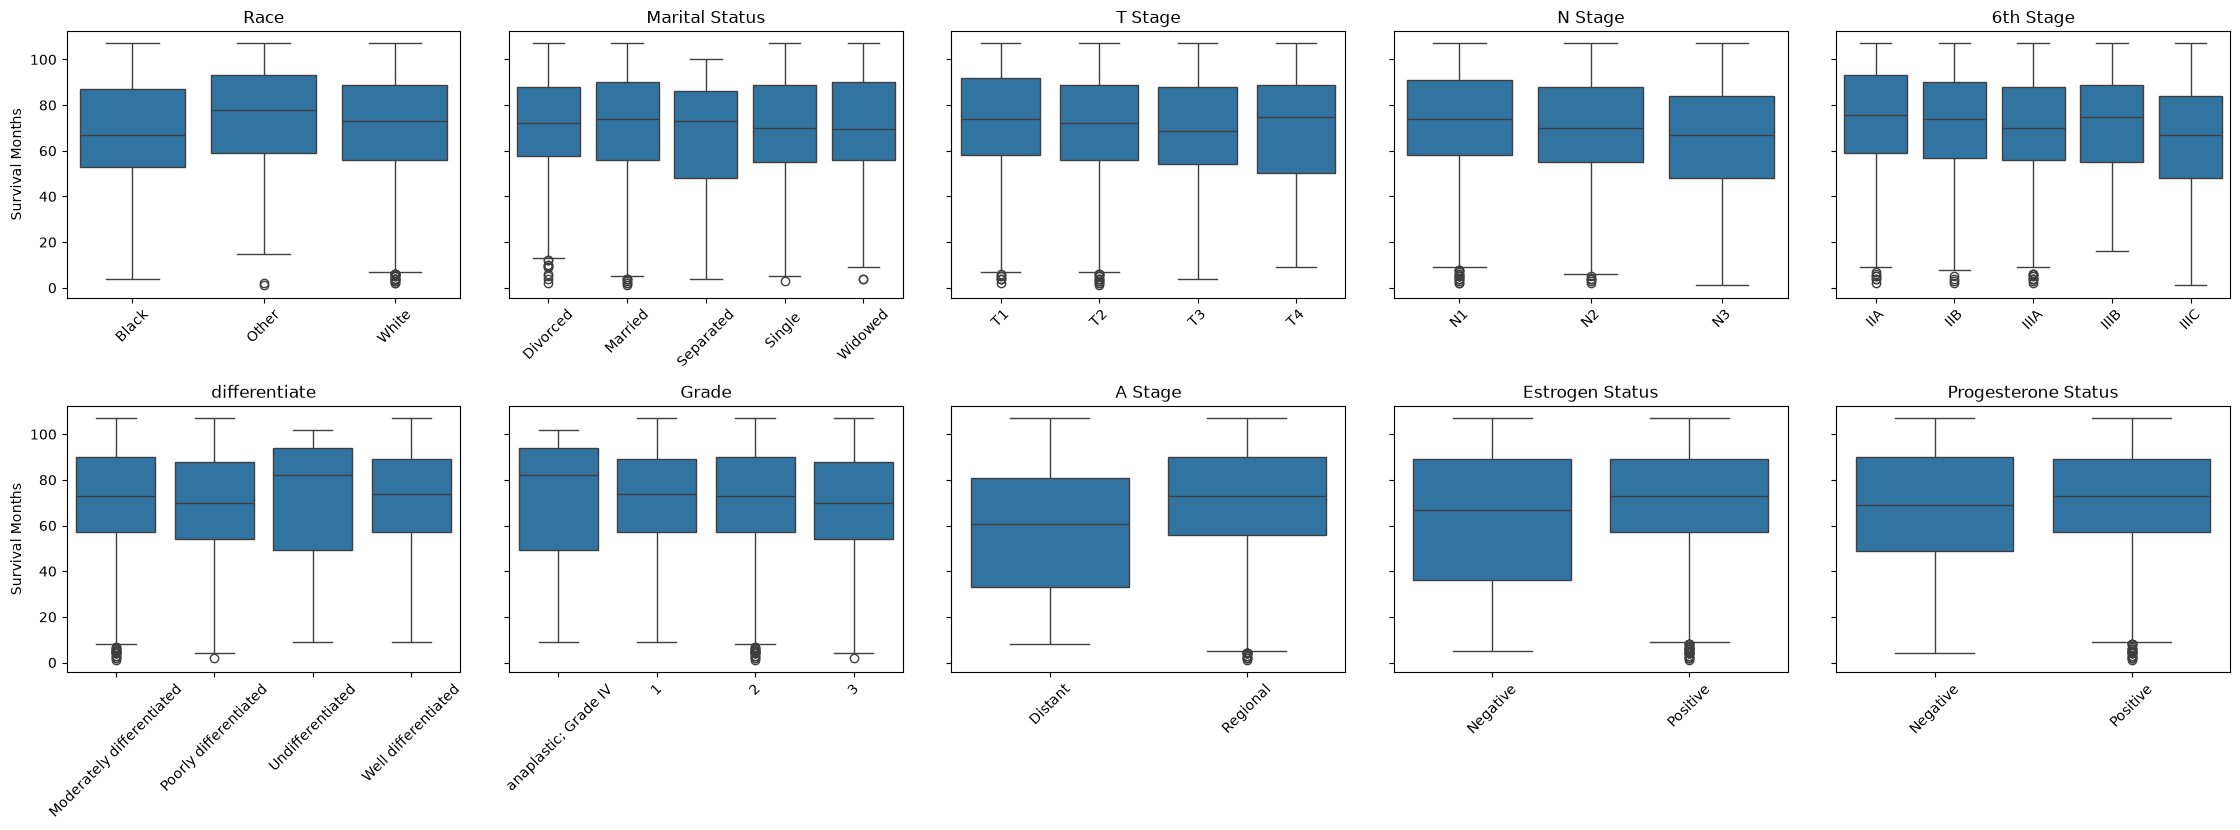

In [37]:
# Meses de supervivencia según la categoría de cada variable
n_cols = 5
n_filas = int(np.ceil(len(features_cat) / n_cols))
fig, axes = plt.subplots(n_filas, n_cols, figsize=(4.5 * n_cols, 4.2 * n_filas), sharey=True)
axes = np.array(axes).ravel()

for ax, col in zip(axes, features_cat):
    orden = sorted(X_train[col].unique())
    sns.boxplot(x=X_train[col], y=y_train, order=orden, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)

for ax in axes[len(features_cat):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [38]:
# Kruskal-Wallis: ¿cambian los meses entre las categorías? (eta²: cuánto cambian; <0,01 casi nada, 0,01-0,06 poco, >0,06 bastante)
filas = []
for col in features_cat:
    grupos = [g.values for _, g in y_train.groupby(X_train[col])]
    H, p_val = stats.kruskal(*grupos)
    k, n_tot = len(grupos), len(y_train)
    eta2 = (H - k + 1) / (n_tot - k)
    filas.append({'Variable': col, 'p-valor': p_val, 'eta²': eta2})

kw = pd.DataFrame(filas).set_index('Variable').sort_values('eta²', ascending=False)
kw['p-valor'] = kw['p-valor'].map(lambda v: f"{v:.1e}")
kw['eta²'] = kw['eta²'].round(3)
kw

,p-valor,eta²
Variable,,
6th Stage,5.9e-08,0.011
N Stage,5.3e-08,0.010
Estrogen Status,2.8e-04,0.004
T Stage,2.6e-03,0.004
A Stage,5.2e-04,0.003
Race,3.7e-03,0.003
Progesterone Status,1.4e-03,0.003
differentiate,2.4e-02,0.002
Grade,2.4e-02,0.002


Al comparar la supervivencia entre los distintos grupos de pacientes, algunas variables como el estadio del cáncer (6th Stage y N Stage), el estado de los receptores hormonales o el tamaño/extensión del tumor muestran diferencias que son estadísticamente detectables. Sin embargo, estas diferencias son muy pequeñas en términos prácticos.

La información más importante es que ninguna variable explica una parte relevante de la supervivencia por sí sola. Incluso las variables que obtienen los mejores resultados apenas explican alrededor del 1 % de las diferencias observadas entre pacientes. Esto significa que conocer únicamente el estadio, el grado tumoral o el estado hormonal ayuda muy poco a predecir cuántos meses sobrevivirá una paciente concreta.

En conjunto, los resultados indican que la supervivencia depende probablemente de muchos factores combinados y de otras variables que no están incluidas en el conjunto de datos. Esto coincide con el resto de los análisis realizados, donde las correlaciones, el Random Forest y las medidas de asociación también mostraban relaciones débiles con la variable objetivo Survival Months.

- Phi-K: asociación de todas las variables (numéricas y categóricas) con el target y entre sí

In [39]:
df_train = pd.concat([X_train, y_train], axis=1)

phik_matrix = df_train.phik_matrix()

phik_target = (phik_matrix['Survival Months'].drop('Survival Months').sort_values(ascending=False))

print(phik_target)

interval columns not set, guessing: ['Age', 'Tumor Size', 'Regional Node Examined', 'Reginol Node Positive', 'Survival Months']
Estrogen Status           0.278083
Progesterone Status       0.231362
6th Stage                 0.197585
N Stage                   0.186325
Reginol Node Positive     0.181746
A Stage                   0.163300
T Stage                   0.106502
Tumor Size                0.103881
differentiate             0.090631
Grade                     0.090631
Race                      0.072168
Regional Node Examined    0.019908
Marital Status            0.000000
Age                       0.000000
Name: Survival Months, dtype: float64


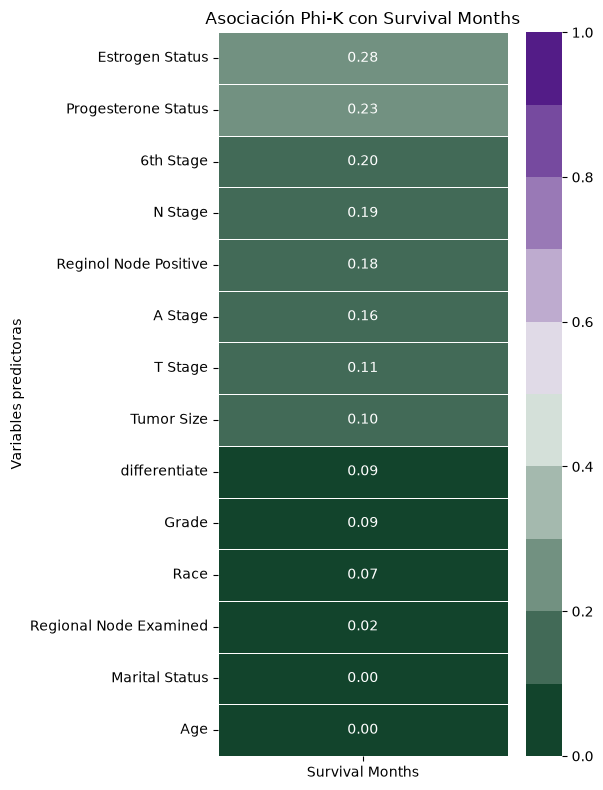

In [40]:
# Heatmap
plt.figure(figsize=(6, 8))

sns.heatmap(
    phik_target.to_frame(),
    vmin=0,
    vmax=1,
    annot=True,
    fmt='.2f',
    cmap=sns.diverging_palette(
        145, 280,
        s=85,
        l=25,
        n=10
    ),
    linewidths=0.5
)

plt.title('Asociación Phi-K con Survival Months')
plt.xlabel('')
plt.ylabel('Variables predictoras')

plt.tight_layout()
plt.show()

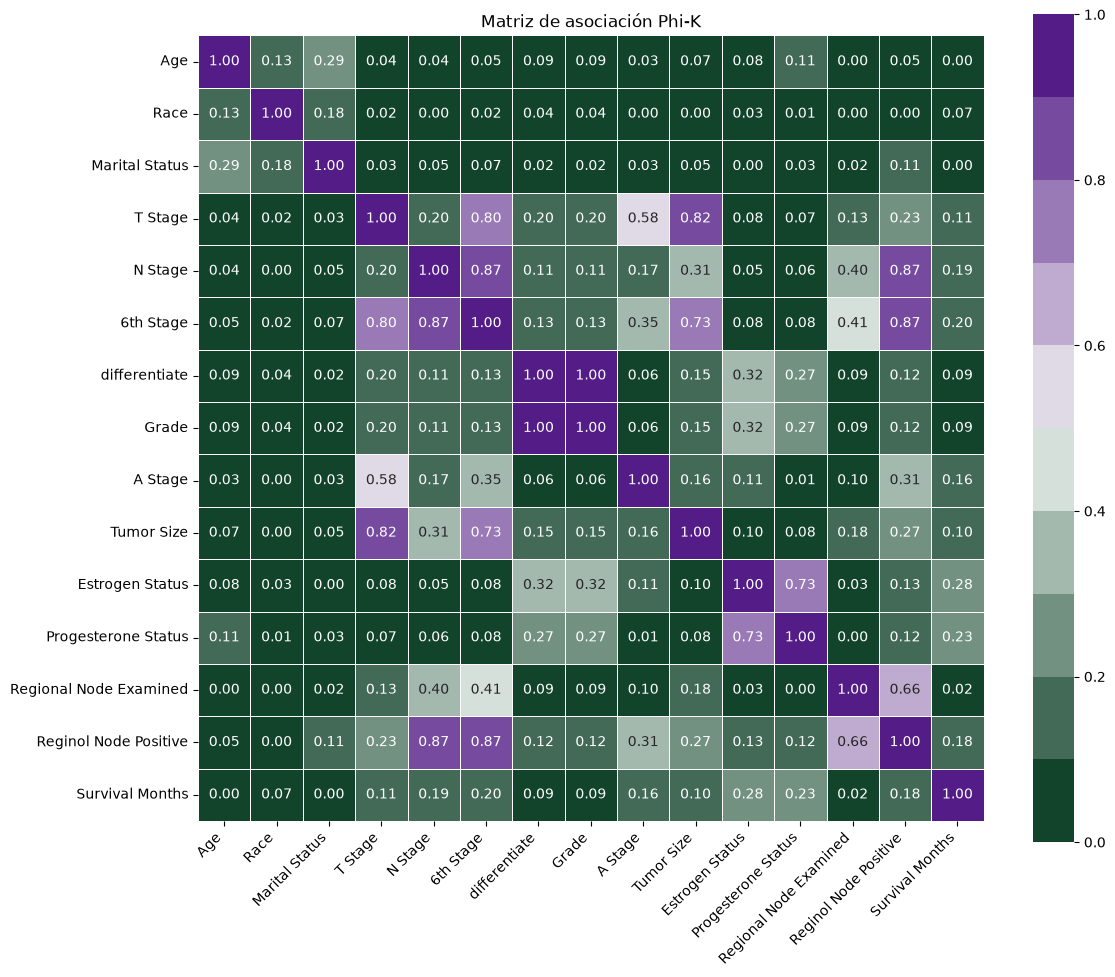

In [41]:
plt.figure(figsize=(12,10))

sns.heatmap(
    phik_matrix,
    vmin=0,
    vmax=1,
    annot=True,
    fmt='.2f',
    cmap=sns.diverging_palette(
        145, 280,
        s=85,
        l=25,
        n=10
    ),
    linewidths=0.5,
    square=True
)

plt.title('Matriz de asociación Phi-K')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

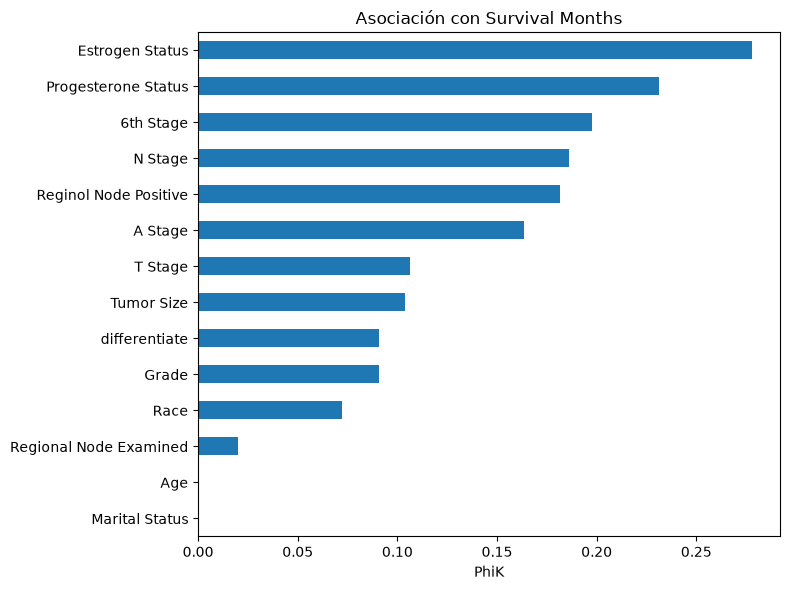

In [42]:
plt.figure(figsize=(8,6))

phik_target.sort_values().plot(kind='barh')

plt.xlabel('PhiK')
plt.title('Asociación con Survival Months')

plt.tight_layout()
plt.show()

In [43]:
# Parejas de predictoras muy asociadas entre sí (Phi-K >= 0,7)
phik_pred = phik_matrix.drop(index='Survival Months', columns='Survival Months')
cols_pred = list(phik_pred.columns)

pares_altos = []
for i, a in enumerate(cols_pred):
    for b in cols_pred[i + 1:]:
        if phik_pred.loc[a, b] >= 0.7:
            pares_altos.append((a, b, phik_pred.loc[a, b]))
pares_altos = sorted(pares_altos, key=lambda x: -x[2])

for a, b, v in pares_altos:
    print(f"{a} - {b}: {v:.2f}")

differentiate - Grade: 1.00
N Stage - Reginol Node Positive: 0.87
6th Stage - Reginol Node Positive: 0.87
N Stage - 6th Stage: 0.87
T Stage - Tumor Size: 0.82
T Stage - 6th Stage: 0.80
Estrogen Status - Progesterone Status: 0.73
6th Stage - Tumor Size: 0.73


Ninguna variable se asocia de forma fuerte con los meses (el máximo es 0.28). Las que más: Estrogen Status (0.28), Progesterone Status (0.23), 6th Stage (0.20), N Stage (0.19), Reginol Node Positive (0.18). Prácticamente nada: Regional Node Examined, Marital Status, Age. Entre las propias predictoras hay parejas que casi se repiten: differentiate - Grade (1.00); N Stage - Reginol Node Positive (0.87); 6th Stage - Reginol Node Positive (0.87); N Stage - 6th Stage (0.87); T Stage - Tumor Size (0.82); T Stage - 6th Stage (0.80). Son variables de estadiaje que describen lo mismo desde distintos ángulos.

- Variables redundantes

In [44]:
pd.crosstab(
    X_train['differentiate'],
    X_train['Grade']
)

Grade,anaplastic; Grade IV,1,2,3
differentiate,,,,
Moderately differentiated,0,0,1867,0
Poorly differentiated,0,0,0,893
Undifferentiated,16,0,0,0
Well differentiated,0,443,0,0


Tal y como explicamos en la introducción, Grade y differenciate aportaban la misma información. El análisis de contingencia entre las variables Grade y differentiate mostró una correspondencia uno a uno entre sus categorías. Asimismo, ambas variables presentaron idénticos valores de asociación PhiK respecto a la variable objetivo. Por tanto, queda comprobado que ambas dan información redundante y procedemos a eliminar una de ellas, differenciate, ya que Grade está como variable categórica ordinal.

In [45]:
X_train = X_train.drop(columns=['differentiate'])
X_test = X_test.drop(columns=['differentiate'])

- Importancia de las variables numéricas: Random Forest y SelectKBest

De las variables numéricas, vemos cuáles son las más importantes.

In [46]:
from sklearn.ensemble import RandomForestRegressor

In [47]:
# Seleccionar solo variables numéricas
X_train_num = X_train.select_dtypes(include=np.number)

# Entrenar Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

rf.fit(X_train_num, y_train)

# Importancia de variables
importancias = pd.DataFrame({'Feature': X_train_num.columns, 'Score': rf.feature_importances_})

# Ordenar de mayor a menor importancia
importancias = importancias.sort_values(by='Score', ascending=False).reset_index(drop=True)

print(importancias)

                  Feature     Score
0                     Age  0.296436
1              Tumor Size  0.284556
2  Regional Node Examined  0.268783
3   Reginol Node Positive  0.150225


In [48]:
# Seleccionar variables numéricas

from sklearn.feature_selection import SelectKBest, f_regression

X_train_num = X_train.select_dtypes(include=np.number)

print("Dimensiones originales:", X_train_num.shape)

# Seleccionar las 3 mejores variables
sel = SelectKBest(score_func=f_regression, k=3)

X_new = sel.fit_transform(X_train_num, y_train)

print("Dimensiones tras selección:", X_new.shape)

# Scores obtenidos
print(sel.scores_)

# Tabla ordenada
scores_df = pd.DataFrame({'Variable': X_train_num.columns, 'Score': sel.scores_})

scores_df = scores_df.sort_values(by='Score', ascending=False).reset_index(drop=True)

print(scores_df)

Dimensiones originales: (3219, 4)
Dimensiones tras selección: (3219, 3)
[ 0.75246094 22.82843471  1.24425131 48.8970297 ]
                 Variable      Score
0   Reginol Node Positive  48.897030
1              Tumor Size  22.828435
2  Regional Node Examined   1.244251
3                     Age   0.752461


Los dos métodos no se ponen de acuerdo. El Random Forest pone primero a Age (30%), el test lineal a Reginol Node Positive y la información mutua a Reginol Node Positive. Las puntuaciones del Random Forest están muy repartidas entre las cuatro (ver tabla), algo típico cuando ninguna variable tiene una relación clara con el target. Este método reparte mejor nota a variables con muchos valores distintos, como la edad, aunque no tengan relación real. Por eso no se debe fiar de él solo; se contrasta abajo con un método más fiable.

- Importancia de todas las variables: Random Forest clásico y permutación

In [49]:
# Codificación de variables categóricas
X_train_dummies = pd.get_dummies(X_train, drop_first=False)

# Entrenamiento
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

rf.fit(X_train_dummies, y_train)

# Importancias
importancias = pd.DataFrame({'Variable': X_train_dummies.columns, 'Importancia': rf.feature_importances_})

importancias = importancias.sort_values(by='Importancia', ascending=False)

# Agrupamos por las categorías originales

resultados = []

for var in X_train.columns:

    columnas = [
        col for col in X_train_dummies.columns
        if col == var or col.startswith(var + "_")
    ]

    importancia = importancias.loc[
        importancias['Variable'].isin(columnas),
        'Importancia'
    ].sum()

    resultados.append([var, importancia])

resultado_final = pd.DataFrame(
    resultados,
    columns=["Variable", "Importancia"]
)

resultado_final = resultado_final.sort_values(
    by="Importancia",
    ascending=False
)

print(resultado_final)

                  Variable  Importancia
0                      Age     0.210214
11  Regional Node Examined     0.197427
8               Tumor Size     0.193168
12   Reginol Node Positive     0.104342
2           Marital Status     0.075365
6                    Grade     0.064911
1                     Race     0.037944
10     Progesterone Status     0.029041
5                6th Stage     0.024447
9          Estrogen Status     0.021618
3                  T Stage     0.020940
4                  N Stage     0.013715
7                  A Stage     0.006869


In [50]:
# ¿Tiene el Random Forest señal real? Validación cruzada solo con train, frente al punto de referencia
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor

cat_cols = X_train.select_dtypes(exclude='number').columns.to_list()

preproceso = ColumnTransformer(
    [('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
    remainder='passthrough'
)

# Modelo de referencia (predice siempre la media)
modelo_dummy = Pipeline([
    ('prep', preproceso),
    ('dummy', DummyRegressor(strategy='mean'))
])

res_dummy = cross_validate(
    modelo_dummy,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    }
)

mae_dummy = -res_dummy["test_MAE"].mean()
r2_dummy = res_dummy["test_R2"].mean()

# Random Forest
modelo_rf = Pipeline([
    ('prep', preproceso),
    ('rf', RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    )),
])

res_rf = cross_validate(
    modelo_rf,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    }
)

mae_rf = -res_rf["test_MAE"].mean()
r2_rf = res_rf["test_R2"].mean()

print(f"Referencia (responder la media): MAE = {mae_dummy:.2f} meses | R² = {r2_dummy:.3f}")
print(f"Random Forest con todas las variables: MAE = {mae_rf:.2f} meses | R² = {r2_rf:.3f}")

Referencia (responder la media): MAE = 18.59 meses | R² = -0.002
Random Forest con todas las variables: MAE = 18.58 meses | R² = 0.004


In [51]:
# Importancia por permutación: se baraja cada variable y se mira cuánto empeora la predicción.
# Se mide en un trozo de train que el modelo no ha visto (el test no se toca).

from sklearn.inspection import permutation_importance

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42)

modelo_rf.fit(X_tr, y_tr)

perm = permutation_importance(modelo_rf, X_val, y_val, n_repeats=10, random_state=42, scoring='r2', n_jobs=-1)

imp_perm = pd.DataFrame({
    'Variable': X_val.columns,
    'Caída de R²': perm.importances_mean,
    'Desviación': perm.importances_std,
}).sort_values('Caída de R²', ascending=False).reset_index(drop=True)

imp_perm.round(4)

,Variable,Caída de R²,Desviación
0,Regional Node Examined,0.0114,0.0066
1,Reginol Node Positive,0.0088,0.0046
2,Estrogen Status,0.0086,0.0033
3,Race,0.0075,0.0019
4,Tumor Size,0.0034,0.0076
5,T Stage,0.0014,0.0012
6,A Stage,0.0004,0.0015
7,N Stage,0.0003,0.0015
8,Grade,-0.0000,0.0037
9,Progesterone Status,-0.0010,0.0024


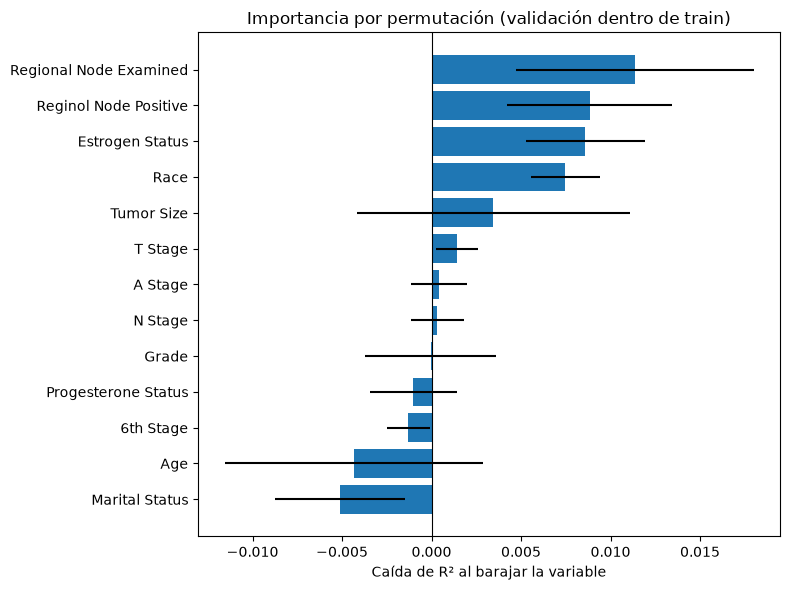

In [52]:
plt.figure(figsize=(8, 6))

orden_perm = imp_perm.sort_values('Caída de R²')
plt.barh(orden_perm['Variable'], orden_perm['Caída de R²'], xerr=orden_perm['Desviación'])
plt.axvline(0, color='black', lw=0.8)

plt.xlabel('Caída de R² al barajar la variable')
plt.title('Importancia por permutación (validación dentro de train)')

plt.tight_layout()
plt.show()

In [53]:
# Comparación de los dos métodos (posición en cada ranking)
comparacion = pd.DataFrame({
    'Puesto Random Forest clásico': resultado_final.set_index('Variable')['Importancia'].rank(ascending=False).astype(int),
    'Puesto permutación': imp_perm.set_index('Variable')['Caída de R²'].rank(ascending=False).astype(int),
}).sort_values('Puesto permutación')
comparacion

,Puesto Random Forest clásico,Puesto permutación
Variable,,
Regional Node Examined,2,1
Reginol Node Positive,4,2
Estrogen Status,10,3
Race,7,4
Tumor Size,3,5
T Stage,11,6
A Stage,13,7
N Stage,12,8
Grade,6,9


El análisis realizado muestra que ninguna variable presenta una capacidad predictiva clara sobre la supervivencia. Aunque el Random Forest clásico asigna mayor importancia a variables como la edad, el número de ganglios examinados, el tamaño tumoral y los ganglios positivos, estos resultados no se confirman mediante métodos más robustos, como la importancia por permutación, las correlaciones o los contrastes estadísticos. Las asociaciones más consistentes se observan en el número de ganglios positivos, el tamaño tumoral, los estadios clínicos y el estado de los receptores hormonales, aunque todas ellas son de magnitud reducida.

Además, la validación cruzada muestra que el Random Forest apenas mejora al modelo de referencia que predice siempre la media de supervivencia (MAE = 18,58 frente a 18,59 meses; R² = 0,004 frente a -0,002). Esto indica que las variables disponibles explican menos del 1 % de la variabilidad de la supervivencia. La limitada capacidad predictiva puede deberse a la homogeneidad de la muestra, la ausencia de variables clínicas relevantes como los tratamientos recibidos y la naturaleza de la variable objetivo, que combina supervivencia y tiempo de seguimiento.

# CONCLUSIONES EDA

## Los datos

Partimos de 4.024 pacientes con cáncer de mama diagnosticadas entre 2006 y 2010, con 16 datos de cada una (edad, tamaño del tumor, ganglios afectados, estadio, receptores hormonales…). No faltaba ningún dato. Había una fila repetida, que se mantuvo porque dos pacientes distintas pueden tener perfiles idénticos.

## Qué queremos predecir

Los meses de supervivencia de cada paciente.

## Una decisión importante

Quitamos la columna que dice si la paciente está viva o fallecida. Ese dato no se conoce cuando se hace la predicción y "delataría" la respuesta, lo que daría resultados falsamente buenos. Como contrapartida, nuestra variable objetivo tiene como limitación mezclar las siguientes situaciones:
 - pacientes fallecidas (supervivencia real).
 - pacientes vivas (solo el tiempo que se las ha seguido).

## Separar en train y test

Dividimos las pacientes en dos grupos: 3.219 para estudiar y entrenar, y 805 reservadas para examinar el modelo al final. Todo el análisis se hizo solo con las 3.219, igual que un examen que no se mira antes de hacerlo.

## Cómo es la supervivencia

La mitad de las pacientes tiene entre 56 y 89 meses; la mediana es 73.
Unas pocas tienen supervivencias muy cortas (24 pacientes por debajo de 7 meses). Las dejamos porque son casos reales, no errores.
La distribución no es una campana. Hay un grupo pequeño con pocos meses y un bloque amplio y parejo hasta los 107. Esto encaja con que parte del dato sea tiempo de seguimiento.
Probamos transformar los meses matemáticamente para "enderezarlos". Mejoraba muy poco y hacía perder la lectura directa en meses, así que no se transformaron.

El listón mínimo: Si respondiéramos siempre la media (71 meses), nos equivocaríamos unos 18,6 meses por paciente. Cualquier modelo tiene que mejorar esa cifra.

## Qué sabemos de los datos

Tumores y ganglios: la mayoría de las pacientes tiene tumores medianos y todas tienen al menos un ganglio afectado. Hay pocos casos extremos, pero existen y se mantienen.
Receptores hormonales: el 93 % tiene estrógenos positivos y el 82 % progesterona positiva, así que los grupos negativos son pequeños.
Categorías muy poco frecuentes: unas pocas tienen menos de 1 % de casos, por ejemplo el grado IV (16 pacientes), y habrá que tratarlas con cuidado.
Edades: van de 30 a 69 años. Las conclusiones solo valen para ese rango.

## Variables que repiten información

Grade y differentiate son lo mismo escrito de dos formas, así que eliminamos differentiate.
Las variables de estadiaje (T, N, 6th Stage, tamaño y ganglios) se solapan mucho porque unas se calculan a partir de otras.
Las numéricas (edad, tamaño, ganglios) no se repiten entre sí.

## Relación con la supervivencia

Ninguna variable explica bien los meses. Las relaciones son muy débiles: más ganglios afectados y tumor más grande se asocian a algo menos de supervivencia, pero con enorme variación entre pacientes. La edad y el estado civil prácticamente no influyen. Los estadios y los receptores hormonales muestran diferencias pequeñas.

## Prueba final

Entrenamos un modelo de prueba (Random Forest) y lo evaluamos con validación cruzada dentro de las pacientes de entrenamiento. Acertó igual que responder siempre la media. Con estos datos no hay, de momento, una pista clara que permita predecir los meses con precisión.

## Por qué puede pasar

Todas las pacientes tienen ganglios afectados, lo que reduce las diferencias entre ellas.
Los meses mezclan supervivencia real y tiempo de seguimiento.
Faltan datos muy influyentes, como el tratamiento o la cirugía.

Las dos primeras razones se apoyan en lo que muestran los datos, y la tercera es una hipótesis. Aun así, el modelo puede seguir siendo un ejercicio válido: el objetivo realista es mejorar de forma modesta el error de 18,6 meses y explicar con honestidad hasta dónde llega.